In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ML_DIR = Path(r"D:\FloodVision-AI\ml")

SRC_DIR = ML_DIR / "src"

PRODUCTION_DIR = ML_DIR / "artifacts/production"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from floodvision.inference.tiling import (
    TilingConfig,
    TileWindow,
    SlidingWindowGenerator,
    TileWeightGenerator
)

config = TilingConfig(
    tile_size=512,
    overlap=128
)

generator = SlidingWindowGenerator(config)

weight_generator = TileWeightGenerator(config)

print("Tile size:", config.tile_size)
print("Overlap:", config.overlap)
print("Stride:", config.stride)

print("\nTiling environment initialized!")

Tile size: 512
Overlap: 128
Stride: 384

Tiling environment initialized!


In [2]:
height = 1024
width = 1024

windows = list(
    generator.generate(
        height=height,
        width=width
    )
)

print("=" * 55)
print("SLIDING WINDOW GENERATION")
print("=" * 55)

print("Raster dimensions:", (height, width))
print("Row positions:", generator.generate_positions(height))
print("Column positions:", generator.generate_positions(width))
print("Total windows:", len(windows))

for window in windows:

    print(
        f"Tile {window.index}: "
        f"row={window.row_off}, "
        f"col={window.col_off}, "
        f"height={window.height}, "
        f"width={window.width}, "
        f"padding={window.requires_padding}"
    )

assert len(windows) == 9

assert len(windows) == generator.count(
    height,
    width
)

print("\nWindow generation PASSED!")

SLIDING WINDOW GENERATION
Raster dimensions: (1024, 1024)
Row positions: [0, 384, 512]
Column positions: [0, 384, 512]
Total windows: 9
Tile 0: row=0, col=0, height=512, width=512, padding=False
Tile 1: row=0, col=384, height=512, width=512, padding=False
Tile 2: row=0, col=512, height=512, width=512, padding=False
Tile 3: row=384, col=0, height=512, width=512, padding=False
Tile 4: row=384, col=384, height=512, width=512, padding=False
Tile 5: row=384, col=512, height=512, width=512, padding=False
Tile 6: row=512, col=0, height=512, width=512, padding=False
Tile 7: row=512, col=384, height=512, width=512, padding=False
Tile 8: row=512, col=512, height=512, width=512, padding=False

Window generation PASSED!


RASTER COVERAGE VALIDATION
Minimum coverage: 1
Maximum coverage: 4
Uncovered pixels: 0
Overlapping pixels: 786432


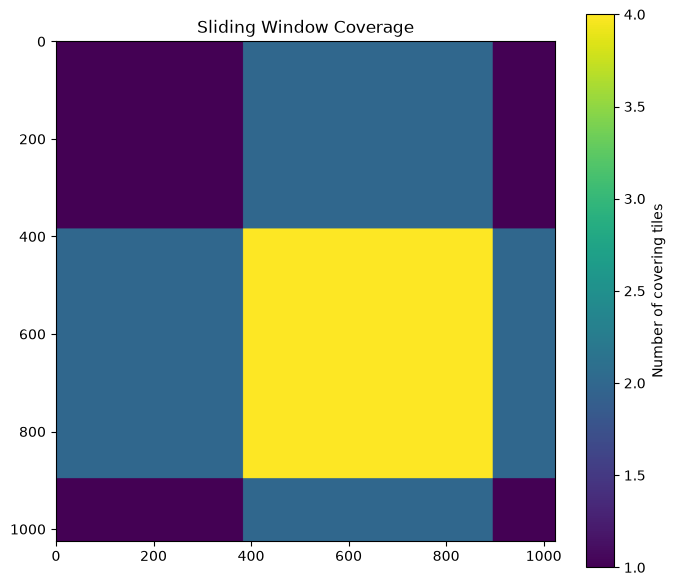


Raster coverage PASSED!


In [3]:
coverage = np.zeros(
    (height, width),
    dtype=np.uint16
)

for window in windows:

    rows, cols = window.raster_slices

    coverage[rows, cols] += 1

print("=" * 55)
print("RASTER COVERAGE VALIDATION")
print("=" * 55)

print("Minimum coverage:", coverage.min())
print("Maximum coverage:", coverage.max())

print(
    "Uncovered pixels:",
    np.count_nonzero(coverage == 0)
)

print(
    "Overlapping pixels:",
    np.count_nonzero(coverage > 1)
)

assert coverage.min() >= 1

plt.figure(figsize=(7, 6))

plt.imshow(
    coverage,
    cmap="viridis"
)

plt.colorbar(
    label="Number of covering tiles"
)

plt.title("Sliding Window Coverage")
plt.tight_layout()
plt.show()

print("\nRaster coverage PASSED!")

In [4]:
test_dimensions = [
    (512, 512),
    (256, 300),
    (512, 1024),
    (1024, 512),
    (700, 900),
    (1024, 1024),
    (1500, 1700),
    (1, 1)
]

print("=" * 55)
print("MULTIPLE RASTER DIMENSION TESTS")
print("=" * 55)

for h, w in test_dimensions:

    test_windows = list(
        generator.generate(h, w)
    )

    test_coverage = np.zeros(
        (h, w),
        dtype=np.uint16
    )

    padded_windows = 0

    for window in test_windows:

        rows, cols = window.raster_slices

        test_coverage[rows, cols] += 1

        if window.requires_padding:

            padded_windows += 1

        assert window.row_end <= h
        assert window.col_end <= w

        assert (
            window.height + window.pad_bottom
            == config.tile_size
        )

        assert (
            window.width + window.pad_right
            == config.tile_size
        )

    assert test_coverage.min() >= 1

    print(
        f"[PASS] {h} x {w} | "
        f"Tiles: {len(test_windows)} | "
        f"Padded: {padded_windows}"
    )

print("\nAll raster dimension tests PASSED!")

MULTIPLE RASTER DIMENSION TESTS
[PASS] 512 x 512 | Tiles: 1 | Padded: 0
[PASS] 256 x 300 | Tiles: 1 | Padded: 1
[PASS] 512 x 1024 | Tiles: 3 | Padded: 0
[PASS] 1024 x 512 | Tiles: 3 | Padded: 0
[PASS] 700 x 900 | Tiles: 6 | Padded: 0
[PASS] 1024 x 1024 | Tiles: 9 | Padded: 0
[PASS] 1500 x 1700 | Tiles: 20 | Padded: 0
[PASS] 1 x 1 | Tiles: 1 | Padded: 1

All raster dimension tests PASSED!


BLENDING WEIGHT VALIDATION
Shape: (512, 512)
Dtype: float32
Minimum: 0.001
Maximum: 1.0
Center weight: 1.0
Corner weight: 0.001


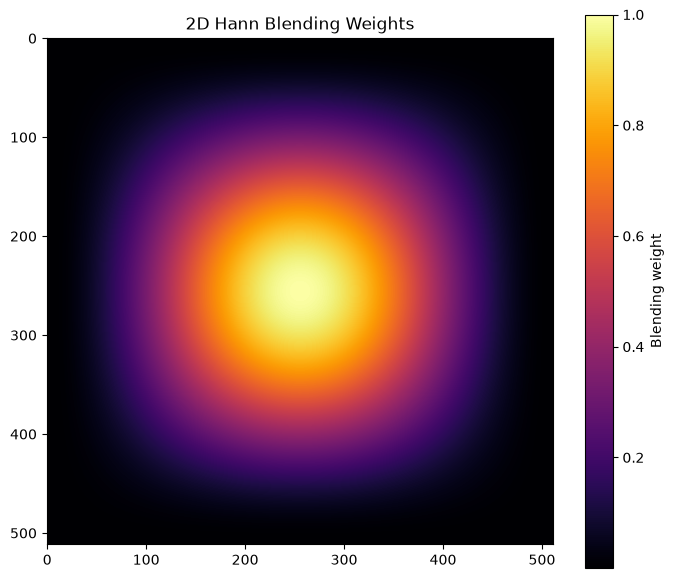


Blending weight validation PASSED!


In [5]:
weights = weight_generator.get_weights()

print("=" * 55)
print("BLENDING WEIGHT VALIDATION")
print("=" * 55)

print("Shape:", weights.shape)
print("Dtype:", weights.dtype)
print("Minimum:", weights.min())
print("Maximum:", weights.max())
print("Center weight:", weights[256, 256])
print("Corner weight:", weights[0, 0])

assert weights.shape == (512, 512)
assert weights.dtype == np.float32
assert np.isfinite(weights).all()
assert (weights > 0).all()
assert weights.max() <= 1.0

assert weights[256, 256] > weights[0, 0]

plt.figure(figsize=(7, 6))

plt.imshow(
    weights,
    cmap="inferno"
)

plt.colorbar(label="Blending weight")
plt.title("2D Hann Blending Weights")

plt.tight_layout()
plt.show()

print("\nBlending weight validation PASSED!")

COMBINED BLENDING COVERAGE
Minimum weight sum: 0.001
Maximum weight sum: 2.910511
Zero-weight pixels: 0


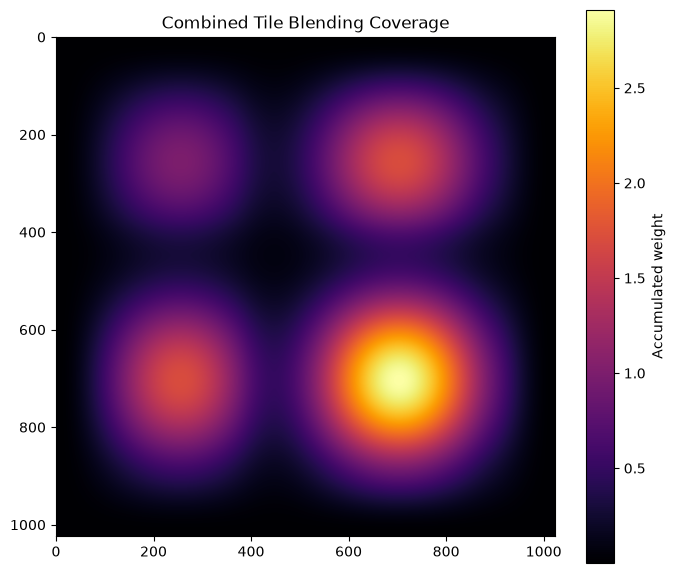


Combined blending coverage PASSED!


In [6]:
weight_sum = np.zeros(
    (1024, 1024),
    dtype=np.float32
)

for window in windows:

    rows, cols = window.raster_slices

    tile_weights = (
        weight_generator.get_weights(window)
    )

    weight_sum[rows, cols] += tile_weights

print("=" * 55)
print("COMBINED BLENDING COVERAGE")
print("=" * 55)

print("Minimum weight sum:", weight_sum.min())
print("Maximum weight sum:", weight_sum.max())

print(
    "Zero-weight pixels:",
    np.count_nonzero(weight_sum == 0)
)

assert np.isfinite(weight_sum).all()
assert (weight_sum > 0).all()

plt.figure(figsize=(7, 6))
plt.imshow(weight_sum, cmap="inferno")
plt.colorbar(label="Accumulated weight")
plt.title("Combined Tile Blending Coverage")
plt.tight_layout()
plt.show()

print("\nCombined blending coverage PASSED!")

In [7]:
import pandas as pd
import yaml
import rasterio

from floodvision.inference.tile_reader import (
    RasterTileReader
)

reader = RasterTileReader(
    config=config,
    require_crs=True,
    allow_unverified_band_order=False
)

dataset_config = yaml.safe_load(
    (ML_DIR / "configs/dataset.yaml").read_text(
        encoding="utf-8"
    )
)["dataset"]

val_samples = pd.read_csv(
    ML_DIR / "data/splits/geographical/val.csv"
)

sample_id = val_samples.iloc[0]["sample_id"]

sample_path = (
    ML_DIR
    / dataset_config["root_dir"]
    / dataset_config["image_dir"]
    / f"{sample_id}_S1Hand.tif"
)

metadata = reader.get_metadata(sample_path)

print("Sample:", sample_id)
print("Dimensions:", metadata.height, metadata.width)
print("CRS:", metadata.crs)
print("Bands:", metadata.band_descriptions)
print("Band order verified:", metadata.band_order_verified)
print("Total tiles:", reader.count_tiles(sample_path))

print("\nRaster tile reader initialized!")

Sample: Mekong_1111068
Dimensions: 512 512
CRS: EPSG:4326
Bands: ('VV', 'VH')
Band order verified: True
Total tiles: 1

Raster tile reader initialized!


In [8]:
from contextlib import closing

with closing(reader.iter_tiles(sample_path)) as stream:

    tile = next(stream)

print("=" * 55)
print("ACTUAL SATELLITE TILE READING")
print("=" * 55)

print("Tile index:", tile.window.index)
print("Image shape:", tile.sar_input.image.shape)
print("Image dtype:", tile.sar_input.image.dtype)

print(
    "Validity mask shape:",
    tile.sar_input.valid_mask.shape
)

print("Valid pixels:", tile.valid_pixels)
print("Padding pixels:", tile.padding_pixels)
print("Empty tile:", tile.is_empty)

print(
    "Tile transform:",
    tile.sar_input.metadata.transform
)

assert tile.sar_input.image.shape == (2, 512, 512)

assert tile.sar_input.image.dtype == np.float32

assert tile.sar_input.valid_mask.shape == (512, 512)

assert tile.padding_pixels == 0

assert not tile.is_empty

assert np.isfinite(tile.sar_input.image).all()

print("\nSatellite tile reading PASSED!")

ACTUAL SATELLITE TILE READING
Tile index: 0
Image shape: (2, 512, 512)
Image dtype: float32
Validity mask shape: (512, 512)
Valid pixels: 262144
Padding pixels: 0
Empty tile: False
Tile transform: | 0.00, 0.00, 105.83|
| 0.00,-0.00, 12.05|
| 0.00, 0.00, 1.00|

Satellite tile reading PASSED!


In [9]:
from floodvision.preprocessing.sar import (
    read_sar_image
)

original_image, original_mask, original_metadata = (
    read_sar_image(sample_path)
)

tile_image = tile.sar_input.image
tile_mask = tile.sar_input.valid_mask

valid_values_match = np.array_equal(
    original_image[:, original_mask],
    tile_image[:, tile_mask]
)

mask_match = np.array_equal(
    original_mask,
    tile_mask
)

transform_match = (
    original_metadata["transform"]
    == tile.sar_input.metadata.transform
)

crs_match = (
    original_metadata["crs"]
    == tile.sar_input.metadata.crs
)

print("=" * 55)
print("ORIGINAL VS TILED READER EQUIVALENCE")
print("=" * 55)

print("Valid SAR values identical:", valid_values_match)
print("Validity masks identical:", mask_match)
print("Transform identical:", transform_match)
print("CRS identical:", crs_match)

assert valid_values_match
assert mask_match
assert transform_match
assert crs_match

print("\nRaster reading equivalence PASSED!")

ORIGINAL VS TILED READER EQUIVALENCE
Valid SAR values identical: True
Validity masks identical: True
Transform identical: True
CRS identical: True

Raster reading equivalence PASSED!


In [10]:
import tempfile

test_directory = tempfile.TemporaryDirectory(
    prefix="floodvision_tiling_"
)

TEST_DIR = Path(test_directory.name)

large_raster_path = TEST_DIR / "synthetic_large_sar.tif"

large_image = np.tile(
    original_image,
    (1, 2, 2)
)

large_valid_mask = np.tile(
    original_mask,
    (2, 2)
)

large_image[:, ~large_valid_mask] = np.nan

# Make the first 512 x 512 region completely invalid.
large_image[:, :512, :512] = np.nan

with rasterio.open(sample_path) as src:

    profile = src.profile.copy()

profile.update(
    driver="GTiff",
    height=1024,
    width=1024,
    count=2,
    dtype="float32",
    nodata=np.nan
)

with rasterio.open(
    large_raster_path,
    "w",
    **profile
) as dst:

    dst.write(large_image)

    dst.set_band_description(1, "VV")
    dst.set_band_description(2, "VH")

print("Synthetic large raster created!")
print("Path:", large_raster_path)
print("Shape:", large_image.shape)

del large_image
del large_valid_mask

Synthetic large raster created!
Path: C:\Users\User\AppData\Local\Temp\floodvision_tiling_epdkw4h4\synthetic_large_sar.tif
Shape: (2, 1024, 1024)


In [12]:
print("=" * 55)
print("LARGE RASTER STREAMING TEST")
print("=" * 55)

total_tiles = 0
empty_tiles = 0
valid_tiles = 0

for large_tile in reader.iter_tiles(
    large_raster_path
):

    total_tiles += 1

    if large_tile.is_empty:

        empty_tiles += 1

        status = "SKIP"

    else:

        valid_tiles += 1

        status = "VALID"

    print(
        f"Tile {large_tile.window.index} | "
        f"Row: {large_tile.window.row_off} | "
        f"Col: {large_tile.window.col_off} | "
        f"Valid pixels: {large_tile.valid_pixels} | "
        f"Status: {status}"
    )

    assert large_tile.sar_input.image.shape == (
        2, 512, 512
    )

    assert np.isfinite(
        large_tile.sar_input.image
    ).all()

print("\nTotal tiles:", total_tiles)
print("Valid tiles:", valid_tiles)
print("Empty tiles:", empty_tiles)

assert total_tiles == 9
assert empty_tiles == 1
assert valid_tiles == 8

print("\nLarge raster streaming PASSED!")

LARGE RASTER STREAMING TEST
Tile 0 | Row: 0 | Col: 0 | Valid pixels: 0 | Status: SKIP
Tile 1 | Row: 0 | Col: 384 | Valid pixels: 196608 | Status: VALID
Tile 2 | Row: 0 | Col: 512 | Valid pixels: 262144 | Status: VALID
Tile 3 | Row: 384 | Col: 0 | Valid pixels: 196608 | Status: VALID
Tile 4 | Row: 384 | Col: 384 | Valid pixels: 245760 | Status: VALID
Tile 5 | Row: 384 | Col: 512 | Valid pixels: 262144 | Status: VALID
Tile 6 | Row: 512 | Col: 0 | Valid pixels: 262144 | Status: VALID
Tile 7 | Row: 512 | Col: 384 | Valid pixels: 262144 | Status: VALID
Tile 8 | Row: 512 | Col: 512 | Valid pixels: 262144 | Status: VALID

Total tiles: 9
Valid tiles: 8
Empty tiles: 1

Large raster streaming PASSED!


In [13]:
small_raster_path = TEST_DIR / "synthetic_small_sar.tif"

small_image = original_image[
    :,
    :256,
    :300
].copy()

small_valid_mask = original_mask[
    :256,
    :300
]

small_image[:, ~small_valid_mask] = np.nan

small_profile = profile.copy()

small_profile.update(
    height=256,
    width=300
)

with rasterio.open(
    small_raster_path,
    "w",
    **small_profile
) as dst:

    dst.write(small_image)

    dst.set_band_description(1, "VV")
    dst.set_band_description(2, "VH")

with closing(
    reader.iter_tiles(small_raster_path)
) as stream:

    small_tile = next(stream)

print("=" * 55)
print("SMALL RASTER PADDING TEST")
print("=" * 55)

print("Original shape:", small_tile.original_shape)
print("Padded shape:", small_tile.sar_input.image.shape)

print("Padding bottom:", small_tile.window.pad_bottom)
print("Padding right:", small_tile.window.pad_right)
print("Padding pixels:", small_tile.padding_pixels)

assert small_tile.original_shape == (256, 300)

assert small_tile.sar_input.image.shape == (
    2, 512, 512
)

assert small_tile.padding_pixels == 185344

assert not small_tile.sar_input.valid_mask[
    256:, :
].any()

assert not small_tile.sar_input.valid_mask[
    :, 300:
].any()

assert np.all(
    small_tile.sar_input.image[:, 256:, :] == 0
)

assert np.all(
    small_tile.sar_input.image[:, :, 300:] == 0
)

print("\nSmall raster padding PASSED!")

SMALL RASTER PADDING TEST
Original shape: (256, 300)
Padded shape: (2, 512, 512)
Padding bottom: 256
Padding right: 212
Padding pixels: 185344

Small raster padding PASSED!


In [14]:
from floodvision.inference.model_loader import (
    ModelLoader
)

from floodvision.inference.preprocessor import (
    SARPreprocessor
)

from floodvision.inference.predictor import (
    FloodPredictor
)

from floodvision.inference.postprocessor import (
    SegmentationPostprocessor
)

loader = ModelLoader(
    bundle_dir=PRODUCTION_DIR
)

model = loader.load(device="auto")

preprocessor = SARPreprocessor(
    config_path=PRODUCTION_DIR / "preprocessing.yaml",
    require_crs=True,
    allow_unverified_band_order=False
)

predictor = FloodPredictor(
    loader=loader,
    device="auto"
)

postprocessor = SegmentationPostprocessor(
    threshold=loader.inference_config["threshold"]
)

print("Production model loaded!")
print("Device:", loader.device)
print("Model cache reused:", predictor.model is model)

print("\nTiled inference components ready!")

Production model loaded!
Device: cpu
Model cache reused: True

Tiled inference components ready!


In [15]:
# Previous production inference approach.
direct_processed = preprocessor(sample_path)

direct_result = postprocessor(
    predictor(direct_processed)
)

# New tiled inference approach.
tiled_processed = preprocessor.preprocess(
    tile.sar_input
)

tiled_result = postprocessor(
    predictor(tiled_processed)
)

tensor_match = torch.equal(
    direct_processed.tensor,
    tiled_processed.tensor
)

mask_match = np.array_equal(
    direct_result.mask,
    tiled_result.mask
)

probability_match = np.allclose(
    direct_result.probabilities,
    tiled_result.probabilities,
    atol=1e-6,
    rtol=1e-5,
    equal_nan=True
)

print("=" * 55)
print("DIRECT VS TILED INFERENCE")
print("=" * 55)

print("Preprocessed tensors identical:", tensor_match)
print("Prediction masks identical:", mask_match)
print("Probabilities match:", probability_match)

print("Direct coverage:", direct_result.water_coverage)
print("Tiled coverage:", tiled_result.water_coverage)

assert tensor_match
assert mask_match
assert probability_match

print("\nSingle-tile inference equivalence PASSED!")

DIRECT VS TILED INFERENCE
Preprocessed tensors identical: True
Prediction masks identical: True
Probabilities match: True
Direct coverage: 25.217437744140625
Tiled coverage: 25.217437744140625

Single-tile inference equivalence PASSED!


In [16]:
small_processed = preprocessor.preprocess(
    small_tile.sar_input
)

small_result = postprocessor(
    predictor(small_processed)
)

cropped_mask = small_result.mask[
    :small_tile.window.height,
    :small_tile.window.width
]

cropped_probabilities = small_result.probabilities[
    :small_tile.window.height,
    :small_tile.window.width
]

print("=" * 55)
print("PADDED TILE INFERENCE")
print("=" * 55)

print("Model output shape:", small_result.mask.shape)
print("Cropped mask shape:", cropped_mask.shape)

print(
    "Cropped probability shape:",
    cropped_probabilities.shape
)

assert cropped_mask.shape == (256, 300)

assert cropped_probabilities.shape == (256, 300)

assert np.all(
    small_result.mask[256:, :] == -1
)

assert np.all(
    small_result.mask[:, 300:] == -1
)

assert np.isnan(
    small_result.probabilities[256:, :]
).all()

assert np.isnan(
    small_result.probabilities[:, 300:]
).all()

print("\nPadded tile inference PASSED!")

PADDED TILE INFERENCE
Model output shape: (512, 512)
Cropped mask shape: (256, 300)
Cropped probability shape: (256, 300)

Padded tile inference PASSED!


In [17]:
from floodvision.inference.accumulator import (
    WeightedProbabilityAccumulator
)

accumulator = WeightedProbabilityAccumulator(
    height=1024,
    width=1024,
    storage="memory"
)

print("Accumulator initialized!")
print("Shape:", accumulator.shape)
print("Storage:", accumulator.storage)

print(
    "Probability sum:",
    accumulator.probability_sum.sum()
)

print(
    "Weight sum:",
    accumulator.weight_sum.sum()
)

assert accumulator.probability_sum.sum() == 0
assert accumulator.weight_sum.sum() == 0

print("\nAccumulator initialization PASSED!")

accumulator.close()

Accumulator initialized!
Shape: (1024, 1024)
Storage: memory
Probability sum: 0.0
Weight sum: 0.0

Accumulator initialization PASSED!


In [18]:
test_window = TileWindow(
    index=0,
    row_off=0,
    col_off=0,
    height=2,
    width=2,
    tile_size=512
)

with WeightedProbabilityAccumulator(
    height=2,
    width=2
) as acc:

    acc.add(
        window=test_window,
        probabilities=np.full(
            (2, 2), 0.8, dtype=np.float32
        ),
        valid_mask=np.ones(
            (2, 2), dtype=bool
        ),
        weights=np.full(
            (2, 2), 0.9, dtype=np.float32
        )
    )

    acc.add(
        window=test_window,
        probabilities=np.full(
            (2, 2), 0.3, dtype=np.float32
        ),
        valid_mask=np.ones(
            (2, 2), dtype=bool
        ),
        weights=np.full(
            (2, 2), 0.2, dtype=np.float32
        )
    )

    test_mask, test_probs, test_stats = (
        acc.finalize()
    )

    expected = (
        (0.8 * 0.9 + 0.3 * 0.2)
        / (0.9 + 0.2)
    )

    print("Expected probability:", expected)
    print("Actual probabilities:\n", test_probs)
    print("Final mask:\n", test_mask)

    assert np.allclose(
        test_probs,
        expected
    )

    assert np.all(test_mask == 1)

    print("\nWeighted blending PASSED!")

Expected probability: 0.7090909090909091
Actual probabilities:
 [[0.7090909 0.7090909]
 [0.7090909 0.7090909]]
Final mask:
 [[1 1]
 [1 1]]

Weighted blending PASSED!


In [19]:
with WeightedProbabilityAccumulator(
    height=2,
    width=2
) as acc:

    test_probabilities = np.array(
        [
            [0.8, np.nan],
            [0.3, np.nan]
        ],
        dtype=np.float32
    )

    test_validity = np.array(
        [
            [True, False],
            [True, False]
        ],
        dtype=bool
    )

    acc.add(
        window=test_window,
        probabilities=test_probabilities,
        valid_mask=test_validity,
        weights=np.ones(
            (2, 2),
            dtype=np.float32
        )
    )

    test_mask, test_probs, test_stats = (
        acc.finalize()
    )

    print("Final mask:\n", test_mask)
    print("Final probabilities:\n", test_probs)
    print("Statistics:", test_stats)

    assert np.array_equal(
        test_mask,
        np.array([
            [1, -1],
            [0, -1]
        ])
    )

    assert np.isnan(
        test_probs[:, 1]
    ).all()

    assert test_stats["valid_pixels"] == 2
    assert test_stats["invalid_pixels"] == 2
    assert test_stats["water_coverage"] == 50.0

    print("\nInvalid probability handling PASSED!")

Final mask:
 [[ 1 -1]
 [ 0 -1]]
Final probabilities:
 [[0.8 nan]
 [0.3 nan]]
Statistics: {'total_pixels': 4, 'valid_pixels': 2, 'invalid_pixels': 2, 'water_pixels': 1, 'non_water_pixels': 1, 'water_coverage': 50.0, 'non_water_coverage': 50.0, 'valid_percentage': 50.0, 'mean_water_probability': 0.550000011920929, 'tiles_added': 1}

Invalid probability handling PASSED!


In [20]:
import time

large_metadata = reader.get_metadata(
    large_raster_path
)

total_tiles = 0
processed_tiles = 0
skipped_tiles = 0

total_inference_ms = 0.0

start_time = time.perf_counter()

with WeightedProbabilityAccumulator(
    height=large_metadata.height,
    width=large_metadata.width,
    storage="memory"
) as acc:

    for raster_tile in reader.iter_tiles(
        large_raster_path
    ):

        total_tiles += 1

        window = raster_tile.window

        if raster_tile.is_empty:

            skipped_tiles += 1

            print(
                f"Tile {window.index}: SKIPPED"
            )

            continue

        processed_tile = preprocessor.preprocess(
            raster_tile.sar_input
        )

        raw = predictor(processed_tile)

        tile_result = postprocessor(raw)

        h = window.height
        w = window.width

        cropped_probabilities = (
            tile_result.probabilities[:h, :w]
        )

        cropped_validity = (
            tile_result.valid_mask[:h, :w]
        )

        tile_weights = (
            weight_generator.get_weights(window)
        )

        acc.add(
            window=window,
            probabilities=cropped_probabilities,
            valid_mask=cropped_validity,
            weights=tile_weights
        )

        processed_tiles += 1

        total_inference_ms += (
            raw.inference_time_ms
        )

        print(
            f"Tile {window.index}: PROCESSED | "
            f"{raw.inference_time_ms:.2f} ms"
        )

    large_mask, large_probabilities, large_stats = (
        acc.finalize(
            threshold=loader.inference_config["threshold"]
        )
    )

elapsed_ms = (
    time.perf_counter() - start_time
) * 1000

print("\n" + "=" * 55)
print("COMPLETE LARGE RASTER INFERENCE")
print("=" * 55)

print("Original shape:", large_metadata.height,
      large_metadata.width)

print("Final mask shape:", large_mask.shape)
print("Probability shape:", large_probabilities.shape)

print("Labels:", np.unique(large_mask))

print("\nTotal tiles:", total_tiles)
print("Processed tiles:", processed_tiles)
print("Skipped tiles:", skipped_tiles)

for key, value in large_stats.items():
    print(f"{key}: {value}")

print(
    f"\nTotal model inference: "
    f"{total_inference_ms:.2f} ms"
)

print(
    f"End-to-end processing: "
    f"{elapsed_ms:.2f} ms"
)

assert large_mask.shape == (1024, 1024)

assert total_tiles == 9
assert processed_tiles == 8
assert skipped_tiles == 1

assert large_stats["total_pixels"] == 1048576

assert large_stats["invalid_pixels"] == 262144

assert large_stats["valid_pixels"] == 786432

print("\nLarge raster inference PASSED!")

Tile 0: SKIPPED
Tile 1: PROCESSED | 580.26 ms
Tile 2: PROCESSED | 247.28 ms
Tile 3: PROCESSED | 335.67 ms
Tile 4: PROCESSED | 147.67 ms
Tile 5: PROCESSED | 157.04 ms
Tile 6: PROCESSED | 250.98 ms
Tile 7: PROCESSED | 157.17 ms
Tile 8: PROCESSED | 133.50 ms

COMPLETE LARGE RASTER INFERENCE
Original shape: 1024 1024
Final mask shape: (1024, 1024)
Probability shape: (1024, 1024)
Labels: [-1  0  1]

Total tiles: 9
Processed tiles: 8
Skipped tiles: 1
total_pixels: 1048576
valid_pixels: 786432
invalid_pixels: 262144
water_pixels: 147505
non_water_pixels: 638927
water_coverage: 18.756230672200523
non_water_coverage: 81.24376932779947
valid_percentage: 75.0
mean_water_probability: 0.211568917579402
tiles_added: 8

Total model inference: 2009.57 ms
End-to-end processing: 3579.61 ms

Large raster inference PASSED!


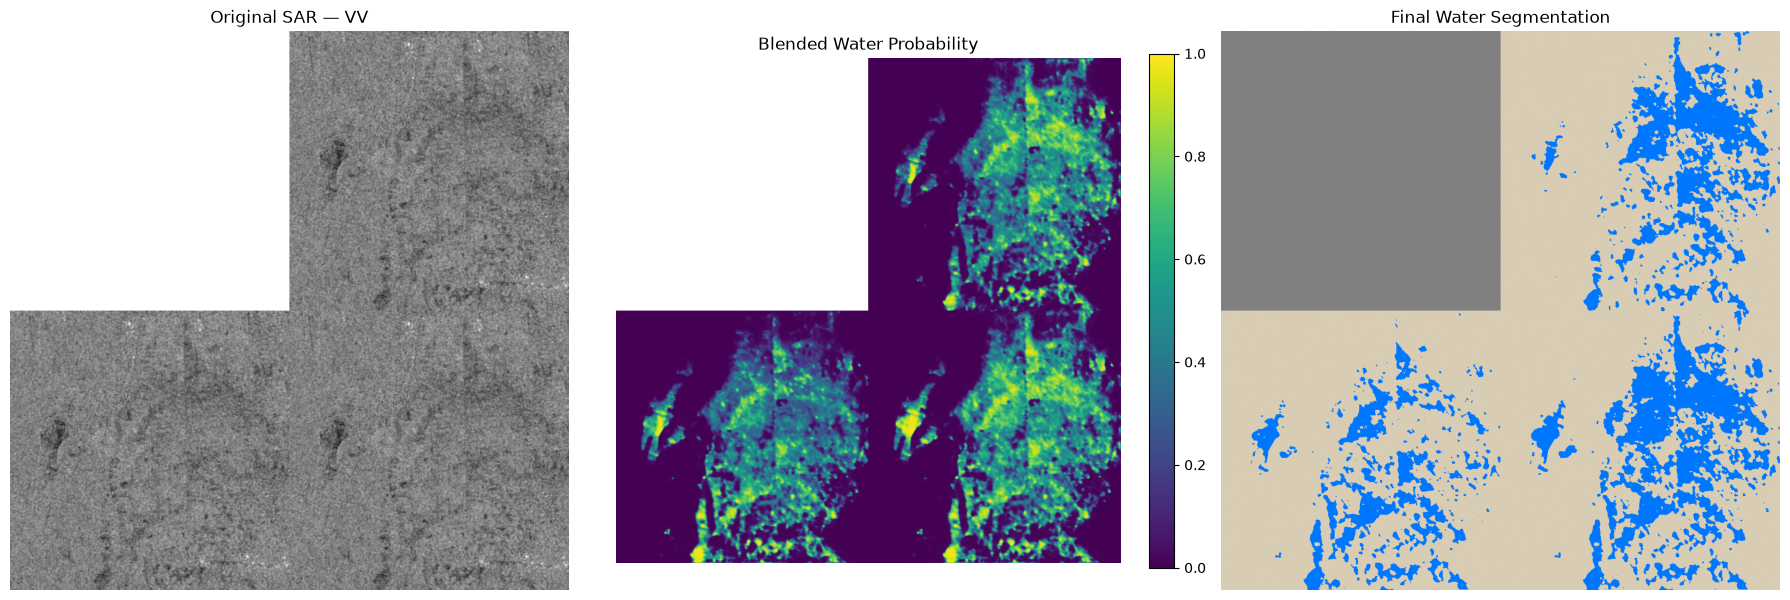

In [21]:
from matplotlib.colors import ListedColormap

with rasterio.open(large_raster_path) as src:

    display_vv = src.read(1)

mask_cmap = ListedColormap([
    "#808080",  # Invalid
    "#d8cdb4",  # Non-water
    "#0077ff"   # Water
])

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

axes[0].imshow(
    display_vv,
    cmap="gray"
)

axes[0].set_title("Original SAR — VV")

prob_plot = axes[1].imshow(
    large_probabilities,
    cmap="viridis",
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "Blended Water Probability"
)

fig.colorbar(
    prob_plot,
    ax=axes[1],
    fraction=0.046
)

axes[2].imshow(
    large_mask,
    cmap=mask_cmap,
    vmin=-1,
    vmax=1
)

axes[2].set_title(
    "Final Water Segmentation"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
with rasterio.open(large_raster_path) as src:

    original_validity = (
        (src.read_masks() > 0).all(axis=0)
        & np.isfinite(src.read()).all(axis=0)
    )

final_validity = large_mask != -1

assert np.array_equal(
    original_validity,
    final_validity
)

assert np.isnan(
    large_probabilities[~original_validity]
).all()

assert np.isfinite(
    large_probabilities[original_validity]
).all()

assert np.all(
    large_probabilities[original_validity] >= 0
)

assert np.all(
    large_probabilities[original_validity] <= 1
)

assert np.all(
    large_mask[:512, :512] == -1
)

print("[PASS] Original validity preserved")
print("[PASS] Invalid probabilities preserved")
print("[PASS] Valid probabilities finite")
print("[PASS] Probability range")
print("[PASS] Completely invalid region preserved")

print("\nFinal raster validity PASSED!")

[PASS] Original validity preserved
[PASS] Invalid probabilities preserved
[PASS] Valid probabilities finite
[PASS] Probability range
[PASS] Completely invalid region preserved

Final raster validity PASSED!


In [23]:
def run_accumulator_test(storage):

    with WeightedProbabilityAccumulator(
        height=1024,
        width=1024,
        storage=storage,
        work_dir=TEST_DIR
    ) as acc:

        for window in generator.generate(
            1024, 1024
        ):

            shape = (
                window.height,
                window.width
            )

            probability = (
                0.1 + window.index * 0.1
            )

            acc.add(
                window=window,
                probabilities=np.full(
                    shape,
                    probability,
                    dtype=np.float32
                ),
                valid_mask=np.ones(
                    shape,
                    dtype=bool
                ),
                weights=weight_generator.get_weights(
                    window
                )
            )

        mask, probs, stats = acc.finalize(
            chunk_rows=128
        )

        print(
            f"{storage} storage:",
            type(acc.probability_sum).__name__
        )

        # Copy only for this small validation raster.
        # Disk-backed arrays must not be accessed
        # after the accumulator is closed.

        return (
            mask.copy(),
            probs.copy(),
            stats
        )


memory_mask, memory_probs, memory_stats = (
    run_accumulator_test("memory")
)

disk_mask, disk_probs, disk_stats = (
    run_accumulator_test("disk")
)

assert np.array_equal(
    memory_mask,
    disk_mask
)

assert np.array_equal(
    memory_probs,
    disk_probs
)

assert memory_stats == disk_stats

print("\n[PASS] Mask equivalence")
print("[PASS] Probability equivalence")
print("[PASS] Statistics equivalence")

print("\nDisk-backed accumulation PASSED!")

memory storage: ndarray
disk storage: memmap

[PASS] Mask equivalence
[PASS] Probability equivalence
[PASS] Statistics equivalence

Disk-backed accumulation PASSED!


In [24]:
from floodvision.inference.tiled_predictor import (
    TiledInferenceEngine
)

engine = TiledInferenceEngine(
    loader=loader,
    config=config,
    device="auto",
    require_crs=True,
    allow_unverified_band_order=False,
    memory_budget_mib=128
)

assert engine.predictor.model is loader.model

print("Tiled inference engine initialized!")
print("Model cache reused:", engine.predictor.model is loader.model)
print("Tile size:", engine.config.tile_size)
print("Overlap:", engine.config.overlap)
print("Threshold:", engine.threshold)

print("\nEngine initialization PASSED!")

Tiled inference engine initialized!
Model cache reused: True
Tile size: 512
Overlap: 128
Threshold: 0.5

Engine initialization PASSED!


In [25]:
print("=" * 55)
print("AUTOMATIC STORAGE SELECTION")
print("=" * 55)

test_sizes = [
    (512, 512),
    (1024, 1024),
    (2048, 2048),
    (4096, 4096),
    (10000, 10000)
]

for h, w in test_sizes:

    required_mib = (
        h * w * 13 / 1024**2
    )

    storage = engine.resolve_storage(h, w)

    print(
        f"{h} x {w} | "
        f"{required_mib:.2f} MiB | "
        f"Storage: {storage}"
    )

assert engine.resolve_storage(
    1024, 1024
) == "memory"

assert engine.resolve_storage(
    10000, 10000
) == "disk"

print("\nAutomatic storage selection PASSED!")

AUTOMATIC STORAGE SELECTION
512 x 512 | 3.25 MiB | Storage: memory
1024 x 1024 | 13.00 MiB | Storage: memory
2048 x 2048 | 52.00 MiB | Storage: memory
4096 x 4096 | 208.00 MiB | Storage: disk
10000 x 10000 | 1239.78 MiB | Storage: disk

Automatic storage selection PASSED!


In [26]:
import json

with engine.predict(
    large_raster_path,
    storage="auto"
) as result:

    print(
        json.dumps(
            result.to_summary(),
            indent=4,
            allow_nan=False
        )
    )

    assert result.mask.shape == (1024, 1024)

    assert result.total_tiles == 9
    assert result.processed_tiles == 8
    assert result.skipped_tiles == 1

    assert result.statistics["valid_pixels"] == 786432

    assert result.statistics["invalid_pixels"] == 262144

    assert np.array_equal(
        result.mask,
        large_mask
    )

    assert np.allclose(
        result.probabilities,
        large_probabilities,
        atol=1e-6,
        rtol=1e-5,
        equal_nan=True
    )

print("\nProduction tiled inference engine PASSED!")

{
    "source_file": "synthetic_large_sar.tif",
    "model_version": "1.0.0",
    "device": "cpu",
    "threshold": 0.5,
    "width": 1024,
    "height": 1024,
    "crs": "EPSG:4326",
    "band_order_verified": true,
    "tiling": {
        "tile_size": 512,
        "overlap": 128,
        "stride": 384,
        "storage": "memory",
        "total_tiles": 9,
        "processed_tiles": 8,
        "skipped_tiles": 1
    },
    "statistics": {
        "total_pixels": 1048576,
        "valid_pixels": 786432,
        "invalid_pixels": 262144,
        "water_pixels": 147505,
        "non_water_pixels": 638927,
        "water_coverage": 18.756230672200523,
        "non_water_coverage": 81.24376932779947,
        "valid_percentage": 75.0,
        "mean_water_probability": 0.211568917579402,
        "tiles_added": 8
    },
    "timing": {
        "inference_ms": 2480.0233999849297,
        "average_tile_inference_ms": 310.0029249981162,
        "processing_ms": 3349.8360000085086
    }
}

Produ

In [27]:
with engine.predict(
    large_raster_path,
    storage="disk",
    work_dir=TEST_DIR
) as result:

    print("Storage:", result.storage)
    print("Mask type:", type(result.mask).__name__)
    print(
        "Probability type:",
        type(result.probabilities).__name__
    )

    assert isinstance(
        result.mask,
        np.memmap
    )

    assert isinstance(
        result.probabilities,
        np.memmap
    )

    assert np.array_equal(
        result.mask,
        large_mask
    )

    assert np.allclose(
        result.probabilities,
        large_probabilities,
        atol=1e-6,
        rtol=1e-5,
        equal_nan=True
    )

    print("Water coverage:", result.water_coverage)

    print("[PASS] Mask equivalence")
    print("[PASS] Probability equivalence")

# Do not access disk-backed result arrays here.

remaining_directories = list(
    TEST_DIR.glob("floodvision_accumulator_*")
)

assert len(remaining_directories) == 0

print("[PASS] Temporary resource cleanup")

print("\nDisk-backed production inference PASSED!")

Storage: disk
Mask type: memmap
Probability type: memmap
Water coverage: 18.756230672200523
[PASS] Mask equivalence
[PASS] Probability equivalence
[PASS] Temporary resource cleanup

Disk-backed production inference PASSED!


In [28]:
with engine.predict(
    sample_path,
    storage="memory"
) as result:

    probability_difference = np.nanmax(
        np.abs(
            result.probabilities
            - direct_result.probabilities
        )
    )

    print(
        "Maximum probability difference:",
        probability_difference
    )

    print(
        "Direct water coverage:",
        direct_result.water_coverage
    )

    print(
        "Tiled water coverage:",
        result.water_coverage
    )

    assert result.total_tiles == 1

    assert np.array_equal(
        result.mask,
        direct_result.mask
    )

    assert np.allclose(
        result.probabilities,
        direct_result.probabilities,
        atol=1e-6,
        rtol=1e-5,
        equal_nan=True
    )

print("\nFull single-tile equivalence PASSED!")

Maximum probability difference: 5.9604645e-08
Direct water coverage: 25.217437744140625
Tiled water coverage: 25.217437744140625

Full single-tile equivalence PASSED!


In [29]:
invalid_raster_path = (
    TEST_DIR / "completely_invalid_sar.tif"
)

invalid_profile = profile.copy()

invalid_profile.update(
    height=512,
    width=512,
    nodata=np.nan
)

with rasterio.open(
    invalid_raster_path,
    "w",
    **invalid_profile
) as dst:

    dst.write(
        np.full(
            (2, 512, 512),
            np.nan,
            dtype=np.float32
        )
    )

    dst.set_band_description(1, "VV")
    dst.set_band_description(2, "VH")

with engine.predict(
    invalid_raster_path
) as result:

    assert result.total_tiles == 1
    assert result.processed_tiles == 0
    assert result.skipped_tiles == 1

    assert result.statistics["valid_pixels"] == 0

    assert result.statistics["invalid_pixels"] == 262144

    assert result.water_coverage is None

    assert np.all(result.mask == -1)

    assert np.isnan(
        result.probabilities
    ).all()

    assert result.inference_time_ms == 0.0

    print(
        json.dumps(
            result.to_summary(),
            indent=4,
            allow_nan=False
        )
    )

print("\nCompletely invalid raster PASSED!")

{
    "source_file": "completely_invalid_sar.tif",
    "model_version": "1.0.0",
    "device": "cpu",
    "threshold": 0.5,
    "width": 512,
    "height": 512,
    "crs": "EPSG:4326",
    "band_order_verified": true,
    "tiling": {
        "tile_size": 512,
        "overlap": 128,
        "stride": 384,
        "storage": "memory",
        "total_tiles": 1,
        "processed_tiles": 0,
        "skipped_tiles": 1
    },
    "statistics": {
        "total_pixels": 262144,
        "valid_pixels": 0,
        "invalid_pixels": 262144,
        "water_pixels": 0,
        "non_water_pixels": 0,
        "water_coverage": null,
        "non_water_coverage": null,
        "valid_percentage": 0.0,
        "mean_water_probability": null,
        "tiles_added": 0
    },
    "timing": {
        "inference_ms": 0.0,
        "average_tile_inference_ms": 0.0,
        "processing_ms": 87.19409996410832
    }
}

Completely invalid raster PASSED!


In [31]:
from floodvision.inference.exceptions import (
    PredictionError
)

def expect_rejection(name, function):

    try:
        function()

    except PredictionError as exc:

        print(f"[PASS] {name}")
        print(f"Reason: {exc}")

    else:

        raise AssertionError(
            f"{name}: Expected rejection."
        )


expect_rejection(
    "Accumulator memory budget exceeded",
    lambda: engine.resolve_storage(
        height=10000,
        width=10000,
        storage="memory"
    )
)


def test_pixel_limit():

    limited_engine = TiledInferenceEngine(
        loader=loader,
        config=config,
        device="auto",
        max_pixels=500000
    )

    with limited_engine.predict(
        large_raster_path
    ):
        pass


expect_rejection(
    "Maximum pixel limit",
    test_pixel_limit
)


def test_tile_limit():

    limited_engine = TiledInferenceEngine(
        loader=loader,
        config=config,
        device="auto",
        max_tiles=4
    )

    with limited_engine.predict(
        large_raster_path
    ):
        pass


expect_rejection(
    "Maximum tile limit",
    test_tile_limit
)

print("\nAll resource rejection tests PASSED!")

[PASS] Accumulator memory budget exceeded
Reason: Raster exceeds accumulator memory budget. Use disk-backed storage.
[PASS] Maximum pixel limit
Reason: Raster exceeds maximum supported pixel count.
[PASS] Maximum tile limit
Reason: Raster exceeds maximum supported tile count.

All resource rejection tests PASSED!


In [32]:
import time
import pandas as pd
import numpy as np

benchmark_records = []

# Warm-up
with engine.predict(
    large_raster_path,
    storage="memory"
):
    pass

for storage in ["memory", "disk"]:

    for run in range(1, 4):

        start = time.perf_counter()

        with engine.predict(
            large_raster_path,
            storage=storage,
            work_dir=TEST_DIR
        ) as result:

            record = {
                "storage": storage,
                "run": run,
                "processed_tiles": result.processed_tiles,
                "inference_ms": result.inference_time_ms,
                "processing_ms": result.processing_time_ms,
                "water_coverage": result.water_coverage
            }

        record["total_with_cleanup_ms"] = (
            time.perf_counter() - start
        ) * 1000

        benchmark_records.append(record)

        print(
            f"{storage.upper()} | Run {run} | "
            f"{record['processing_ms']:.2f} ms"
        )

benchmark_df = pd.DataFrame(
    benchmark_records
)

display(benchmark_df)

MEMORY | Run 1 | 4003.93 ms
MEMORY | Run 2 | 2146.70 ms
MEMORY | Run 3 | 2077.92 ms
DISK | Run 1 | 2531.82 ms
DISK | Run 2 | 2210.00 ms
DISK | Run 3 | 2756.46 ms


,storage,run,processed_tiles,inference_ms,processing_ms,water_coverage,total_with_cleanup_ms
0,memory,1,8,3287.3389,4003.9336,18.756231,4010.9349
1,memory,2,8,1636.8002,2146.6987,18.756231,2155.1818
2,memory,3,8,1608.2496,2077.9160,18.756231,2082.6796
3,disk,1,8,1913.5145,2531.8247,18.756231,2583.3474
4,disk,2,8,1627.6940,2210.0046,18.756231,2251.5596
5,disk,3,8,2017.8693,2756.4583,18.756231,2769.9584


In [33]:
benchmark_summary = (
    benchmark_df
    .groupby("storage")
    .agg(
        mean_inference_ms=("inference_ms", "mean"),
        mean_processing_ms=("processing_ms", "mean"),
        median_processing_ms=("processing_ms", "median"),
        std_processing_ms=("processing_ms", "std"),
        mean_total_ms=("total_with_cleanup_ms", "mean"),
        water_coverage=("water_coverage", "mean")
    )
    .reset_index()
)

display(benchmark_summary.round(4))

assert np.allclose(
    benchmark_df["water_coverage"],
    large_stats["water_coverage"]
)

print("\nPerformance repeatability PASSED!")

,storage,mean_inference_ms,mean_processing_ms,median_processing_ms,std_processing_ms,mean_total_ms,water_coverage
0,disk,1853.0259,2499.4292,2531.8247,274.6635,2534.9551,18.7562
1,memory,2177.4629,2742.8494,2146.6987,1092.6723,2749.5988,18.7562



Performance repeatability PASSED!


In [35]:
import os
import psutil
import threading
import time

process = psutil.Process(os.getpid())


def benchmark_memory(storage):

    stop_event = threading.Event()

    baseline_rss = process.memory_info().rss

    samples = [baseline_rss]

    def monitor():

        while not stop_event.is_set():

            samples.append(
                process.memory_info().rss
            )

            stop_event.wait(0.01)

    monitor_thread = threading.Thread(
        target=monitor,
        daemon=True
    )

    monitor_thread.start()

    try:

        with engine.predict(
            large_raster_path,
            storage=storage,
            work_dir=TEST_DIR
        ) as result:

            samples.append(
                process.memory_info().rss
            )

            coverage = result.water_coverage

    finally:

        stop_event.set()
        monitor_thread.join()

    peak_rss = max(samples)

    return {
        "storage": storage,
        "baseline_rss_mib": baseline_rss / 1024**2,
        "sampled_peak_rss_mib": peak_rss / 1024**2,
        "peak_increase_mib": (
            peak_rss - baseline_rss
        ) / 1024**2,
        "water_coverage": coverage
    }


memory_benchmark_df = pd.DataFrame([
    benchmark_memory("memory"),
    benchmark_memory("disk")
])

display(memory_benchmark_df.round(4))

,storage,baseline_rss_mib,sampled_peak_rss_mib,peak_increase_mib,water_coverage
0,memory,20.5938,191.5039,170.9102,18.7562
1,disk,118.7305,196.0000,77.2695,18.7562


In [36]:
RESULTS_DIR = (
    ML_DIR.parent
    / "research"
    / "experiment-results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

benchmark_df.to_csv(
    RESULTS_DIR / "tiled_inference_benchmark.csv",
    index=False
)

benchmark_summary.to_csv(
    RESULTS_DIR / "tiled_inference_benchmark_summary.csv",
    index=False
)

memory_benchmark_df.to_csv(
    RESULTS_DIR / "tiled_inference_memory_benchmark.csv",
    index=False
)

print("Engineering benchmark results saved!")

Engineering benchmark results saved!


In [37]:

from pathlib import Path
import numpy as np

print("=" * 60)
print("FLOODVISION AI - PHASE 40 FINAL AUDIT")
print("=" * 60)

# 1. Small raster reference prediction

reference = postprocessor(
    predictor(
        preprocessor.preprocess(
            small_tile.sar_input
        )
    )
)

h = small_tile.window.height
w = small_tile.window.width

with engine.predict(
    small_raster_path
) as result:

    assert result.mask.shape == (h, w)

    assert np.array_equal(
        result.mask,
        reference.mask[:h, :w]
    )

    assert np.allclose(
        result.probabilities,
        reference.probabilities[:h, :w],
        atol=1e-6,
        rtol=1e-5,
        equal_nan=True
    )

print("[PASS] Small raster equivalence")


# 2. Benchmark completeness

assert len(benchmark_df) == 6

assert (
    benchmark_df.groupby("storage")
    .size()
    .eq(3)
    .all()
)

print("[PASS] Six benchmark runs")


# 3. Prediction consistency

assert np.allclose(
    benchmark_df["water_coverage"],
    large_stats["water_coverage"]
)

assert np.allclose(
    memory_benchmark_df["water_coverage"],
    large_stats["water_coverage"]
)

print("[PASS] Prediction consistency")


# 4. Save research artifacts

RESULTS_DIR = (
    ML_DIR.parent
    / "research"
    / "experiment-results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

artifacts = {
    "tiled_inference_benchmark.csv":
        benchmark_df,

    "tiled_inference_benchmark_summary.csv":
        benchmark_summary,

    "tiled_inference_memory_benchmark.csv":
        memory_benchmark_df
}

for filename, dataframe in artifacts.items():

    path = RESULTS_DIR / filename

    dataframe.to_csv(
        path,
        index=False
    )

    assert path.is_file()
    assert path.stat().st_size > 0

    print(f"[PASS] {filename}")


# 5. Temporary resource cleanup

assert not list(
    TEST_DIR.glob(
        "floodvision_accumulator_*"
    )
)

print("[PASS] Accumulator resource cleanup")

print("\n" + "=" * 60)
print("PHASE 40 COMPLETED SUCCESSFULLY")
print("=" * 60)


FLOODVISION AI - PHASE 40 FINAL AUDIT
[PASS] Small raster equivalence
[PASS] Six benchmark runs
[PASS] Prediction consistency
[PASS] tiled_inference_benchmark.csv
[PASS] tiled_inference_benchmark_summary.csv
[PASS] tiled_inference_memory_benchmark.csv
[PASS] Accumulator resource cleanup

PHASE 40 COMPLETED SUCCESSFULLY
